# Modelo de xG (Expected Goals) com Machine Learning

**xG** é a probabilidade de um chute virar gol, estimada a partir das características do lance: onde a bola estava, com que parte do corpo foi o chute, como veio a assistência, onde estavam o goleiro e os defensores... Clubes usam xG para avaliar a qualidade das chances criadas e cedidas, sem depender só do placar.

**Objetivo:** treinar um modelo de xG próprio com dados públicos e comparar com o xG oficial da StatsBomb, que é referência de mercado.

**Dados:** todos os chutes do [StatsBomb Open Data](https://github.com/statsbomb/open-data): cerca de 100 mil chutes de 3.961 partidas (masculino e feminino, sem pênaltis).

**Modelos:**
1. *Baseline:* regressão logística só com distância e ângulo (o xG "de livro").
2. *Regressão logística completa*, com todas as variáveis.
3. *Gradient boosting* (`HistGradientBoostingClassifier`), que captura interações não lineares.

In [1]:
import sys; sys.path.append("..")
import pandas as pd
from pathlib import Path
from sklearn.inspection import permutation_importance
from src.model import (load_shots, train_all, cross_validate, xg_grid, mask_sparse, finishing_table, FEATURES)
from src import viz

pd.set_option("display.precision", 4)
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)

csv = Path("../data/processed/shots.csv")
if not csv.exists():                      # na 1ª execução, extrai os chutes (~3 min)
    from src.extract import build; build()
df = load_shots(csv)
print(f"{len(df):,} chutes · {df['match_id'].nunique():,} partidas · taxa de gol {df['goal'].mean():.1%}")

99,710 chutes · 3,961 partidas · taxa de gol 10.2%


## 1. Variáveis do modelo

| Grupo | Variáveis |
|---|---|
| Geometria | distância ao gol, ângulo de abertura do gol, posição (profundidade e lateral) |
| Tipo de chute | parte do corpo, técnica (voleio, cobertura...), bola rolando ou falta direta |
| Contexto | origem da jogada (contra-ataque, escanteio...), tipo de assistência (enfiada, cruzamento, cruzamento rasteiro...), sob pressão, de primeira, mano a mano |
| **Freeze frame** (posição dos jogadores no momento do chute) | defensores entre a bola e o gol, marcador mais próximo, adversários a até 5 m, posição do goleiro |

As variáveis de *freeze frame* são o diferencial: um chute da marca do pênalti com três zagueiros na frente vale muito menos que o mesmo chute com o gol livre.

In [2]:
df[["distance", "angle", "n_def_in_cone", "nearest_opp", "gk_dist_shooter", "goal"]].describe().T[["mean", "50%", "min", "max"]]

,mean,50%,min,max
distance,19.0994,18.4068,0.4000,92.8009
angle,0.4465,0.3470,0.0000,3.1416
n_def_in_cone,0.8177,1.0000,0.0000,10.0000
nearest_opp,2.9445,2.2561,0.0000,92.2659
gk_dist_shooter,16.1349,15.0120,0.3162,116.0172
goal,0.1024,0.0000,0.0000,1.0000


## 2. Treino e teste

A divisão é feita **por partida** (80% treino, 20% teste). Chutes do mesmo jogo nunca ficam nos dois lados, para evitar vazamento de informação.

Métricas usadas:
- **Log loss** e **Brier score**: quão boas são as *probabilidades* (menor é melhor). São as métricas certas para xG.
- **ROC AUC**: quão bem o modelo ordena chutes que viram gol acima dos que não viram (maior é melhor).
- **xG total / gols**: se o modelo prevê, no agregado, o número certo de gols (ideal = 1).

In [3]:
fitted, resultados, train, test = train_all(df)
resultados.to_csv("../reports/metricas_teste.csv")
resultados

,log_loss,brier,roc_auc,xg_total/gols
modelo,,,,
Baseline (distância + ângulo),0.2888,0.0820,0.7458,1.0240
Regressão logística,0.2628,0.0745,0.8053,1.0252
Gradient boosting,0.2583,0.0738,0.8143,1.0236
xG da StatsBomb (referência),0.2607,0.0741,0.8094,0.9544


## 3. Validação cruzada (5 folds, agrupada por partida)

Para garantir que o resultado não depende de uma divisão de sorte, repito a avaliação em 5 partes diferentes dos dados e comparo com o xG da StatsBomb em cada uma.

In [4]:
cv, oof = cross_validate(df)
cv[["fold", "modelo_log_loss", "statsbomb_log_loss", "modelo_roc_auc", "statsbomb_roc_auc"]]

,fold,modelo_log_loss,statsbomb_log_loss,modelo_roc_auc,statsbomb_roc_auc
0,1,0.2669,0.2703,0.8055,0.7989
1,2,0.2660,0.2692,0.8068,0.8024
2,3,0.2645,0.2657,0.8127,0.8082
3,4,0.2590,0.2589,0.8113,0.8126
4,5,0.2564,0.2587,0.8163,0.8094


In [5]:
resumo = pd.DataFrame({
    "Este modelo": [cv["modelo_log_loss"].mean(), cv["modelo_brier"].mean(), cv["modelo_roc_auc"].mean()],
    "xG StatsBomb": [cv["statsbomb_log_loss"].mean(), cv["statsbomb_brier"].mean(), cv["statsbomb_roc_auc"].mean()],
}, index=["Log loss", "Brier", "ROC AUC"])
resumo.to_csv("../reports/metricas_cv.csv")
resumo

,Este modelo,xG StatsBomb
Log loss,0.2626,0.2645
Brier,0.0750,0.0752
ROC AUC,0.8105,0.8063


**Leitura:** o gradient boosting fica **no mesmo nível do xG da StatsBomb**, com log loss levemente menor e AUC levemente maior na média dos 5 folds. Ele supera com folga o baseline de distância + ângulo, o que mostra o valor das variáveis de contexto e do freeze frame.

> Ressalva: o modelo da StatsBomb é proprietário e foi treinado com uma base muito maior. Aqui ele serve de *referência*, não de adversário: o ponto é mostrar que o pipeline produz probabilidades de qualidade profissional.

## 4. Calibração

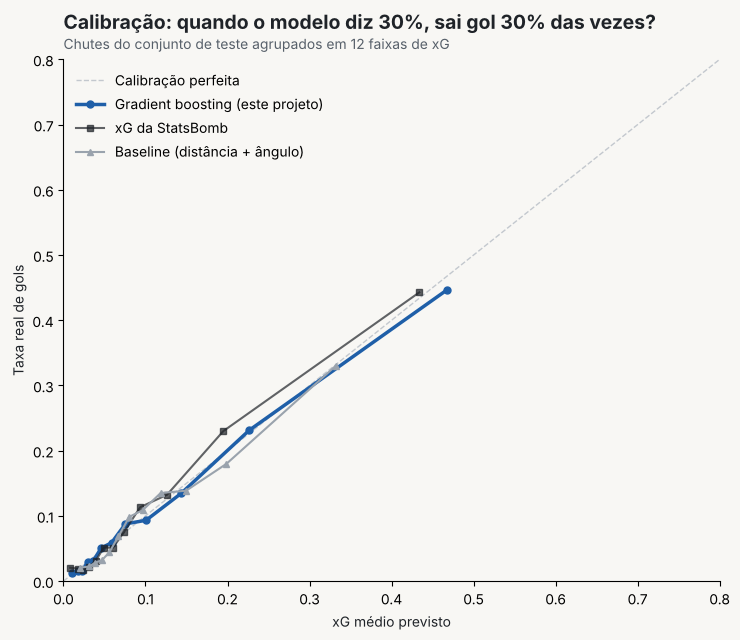

In [6]:
fig = viz.calibration(test, {
    "Gradient boosting (este projeto)": "p_Gradient boosting",
    "xG da StatsBomb": "statsbomb_xg",
    "Baseline (distância + ângulo)": "p_Baseline (distância + ângulo)",
}, save=FIG / "calibracao.png")

## 5. O que mais pesa no xG

Importância por permutação: quanto o log loss piora quando embaralhamos cada variável no conjunto de teste.

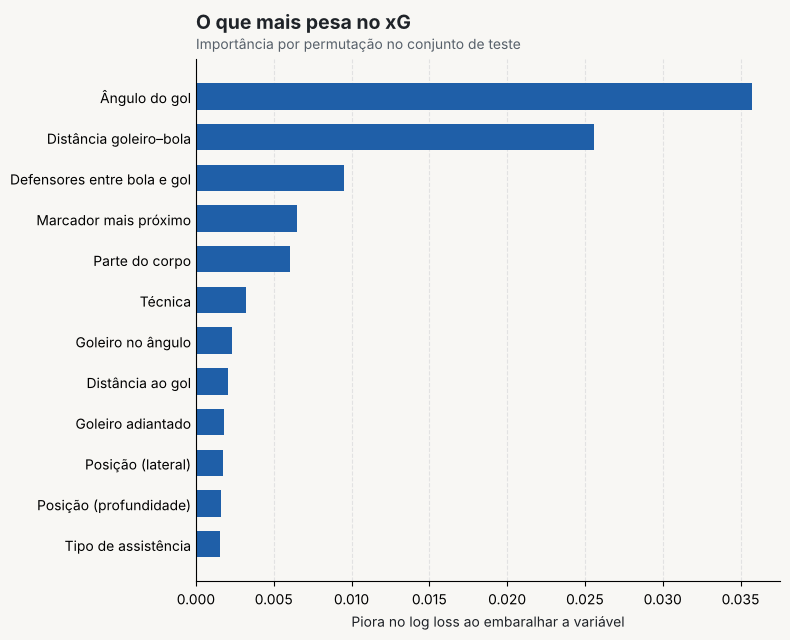

In [7]:
modelo, cols = fitted["Gradient boosting"]
r = permutation_importance(modelo, test[FEATURES], test["goal"], scoring="neg_log_loss", n_repeats=5, random_state=0)
imp = pd.Series(r.importances_mean, index=FEATURES).sort_values(ascending=False)
fig = viz.importance(imp.head(12), save=FIG / "importancia.png")

O **ângulo** e a **distância entre o goleiro e a bola** dominam, seguidos pelos **defensores no caminho**. Ou seja, *onde* estão os outros jogadores importa quase tanto quanto *de onde* sai o chute.

## 6. Mapa de xG

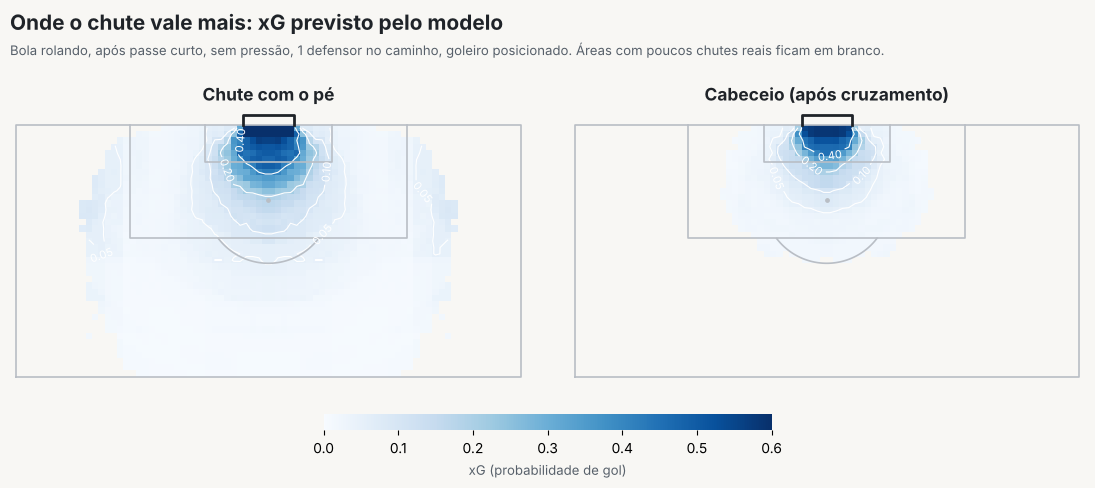

In [8]:
grids = {
    "Chute com o pé": mask_sparse(xg_grid(modelo), df),
    "Cabeceio (após cruzamento)": mask_sparse(xg_grid(modelo, body_part="Head", assist="cruzamento"),
                                              df[df["body_part"] == "Head"], min_shots=8),
}
fig = viz.xg_maps(grids, save=FIG / "mapa_xg.png")

## 7. Aplicação: quem finaliza acima do esperado?

Com as previsões **fora da amostra** da validação cruzada (cada chute é avaliado por um modelo que nunca o viu), comparo os gols de cada jogador com o xG que ele acumulou.

,nome,chutes,gols,xg,diff,desvio_padrao,z
0,Lionel Messi,2583,442,352.5,89.5,15.7,5.7
1,Luis Suárez,628,132,115.2,16.8,8.6,2.0
2,Kylian Mbappé,294,55,42.3,12.7,5.3,2.4
3,Samuel Eto'o,299,63,51.9,11.1,5.6,2.0
4,Zlatan Ibrahimović,224,44,34.4,9.6,4.8,2.0
5,Thierry Henry,352,56,46.6,9.4,5.6,1.7
6,Ousmane Dembélé,176,27,17.7,9.3,3.7,2.5
7,Ivan Rakitić,227,27,17.7,9.3,3.8,2.5
8,Gonzalo Higuaín,196,35,26.9,8.1,4.4,1.8
9,Alexis Sánchez,239,42,34.3,7.7,4.8,1.6


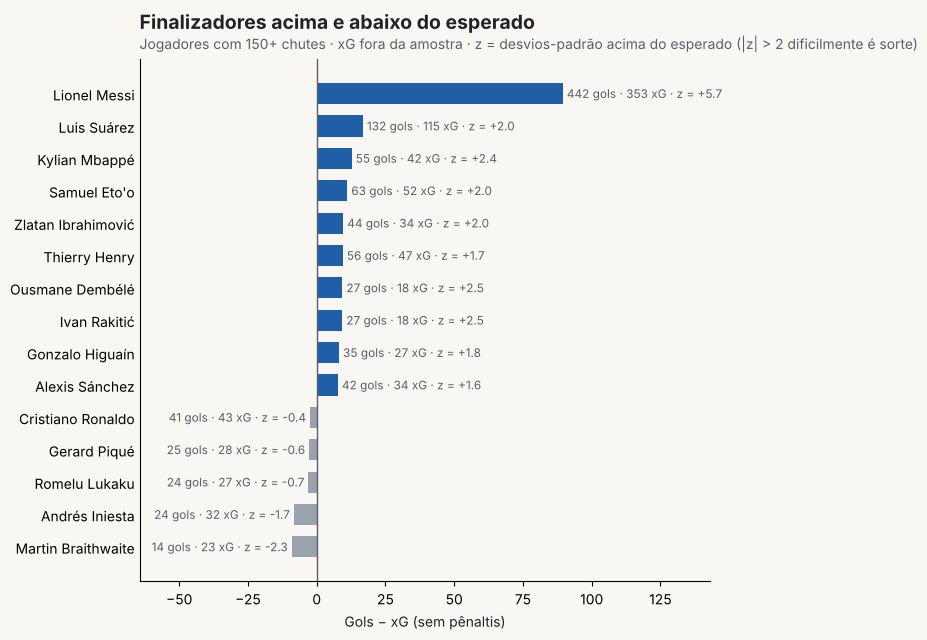

In [9]:
df["xg"] = oof
jog = finishing_table(df[df["gender"] == "male"], min_shots=50)
jog.round(2).to_csv("../data/processed/finalizadores.csv")  # usado no app
jog = jog[jog["chutes"] >= 150]
sel = pd.concat([jog.nlargest(10, "diff"), jog.nsmallest(5, "diff")]).reset_index()
sel["nome"] = sel["player"].map(viz.short_name)
fig = viz.finishing(sel, save=FIG / "finalizadores.png")
sel[["nome", "chutes", "gols", "xg", "diff", "desvio_padrao", "z"]].round(1)

### Habilidade ou sorte? Teste de significância

Um jogador pode marcar acima do xG só por variância. Para separar **habilidade** de **ruído**, cada chute é tratado como uma moeda que vira gol com probabilidade *p* (o xG do chute). Se o jogador finalizasse como a média:

- o número esperado de gols seria **Σ p** (o xG acumulado);
- a variância seria **Σ p(1 − p)** (distribuição Poisson-binomial).

O **z = (gols − xG) / desvio padrão** diz quantos desvios o jogador está acima do esperado. Com |z| > 2, a diferença dificilmente é sorte (menos de ~2,5% de chance em cada direção).

*Sugestão de análise de Diego Arruda nos comentários do post do projeto.*

**Messi** marcou cerca de 90 gols a mais do que o esperado, o que dá **mais de 5 desvios-padrão**. Isso não é variância, é habilidade de finalização. Já casos como Suárez (z ≈ 2) ficam no limite. O Open Data tem praticamente toda a carreira dele em La Liga, e esse é um dos maiores desvios já medidos. O xG mede a qualidade da *chance*, e a diferença para os gols mede a qualidade da *finalização*.

## 8. Limitações e próximos passos

- **Viés da amostra:** o Open Data tem muitos jogos do Barcelona (era Messi) e de algumas competições específicas, então não é uma amostra aleatória do futebol mundial.
- **Regiões raras:** em áreas com poucos chutes (perto da linha de fundo, muito longe do gol) o modelo extrapola, por isso o mapa esconde essas regiões.
- **Próximos passos:** testar XGBoost/LightGBM com busca de hiperparâmetros, calibrar com regressão isotônica, criar um modelo de *post-shot xG* (que considera para onde o chute foi) e aplicar ao Brasileirão quando houver dados.